In [25]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

# =====================================================
# Load data
# =====================================================

with open("output/botorch_train/per_sample_results.json", "r") as f:
    data = json.load(f)

sample_ids = list(data.keys())

# =====================================================
# Containers
# =====================================================

results = []

all_coeff_true = []
all_coeff_pred = []

all_A_true = []
all_A_pred = []

all_Q_true = []
all_Q_pred = []


# =====================================================
# Parse samples
# =====================================================

for sid, sample in data.items():

    coeff_true = np.array(sample["a_matrix_coefficients"])
    coeff_pred = np.array(sample["a_matrix_coefficients_pred"])

    A_true = np.array(sample["a_matrix"])
    A_pred = np.array(sample["a_matrix_pred"])

    Q_true = np.array(sample["q_matrix"])
    Q_pred = np.array(sample["q_pred"])

    all_coeff_true.extend(coeff_true)
    all_coeff_pred.extend(coeff_pred)

    all_A_true.append(A_true)
    all_A_pred.append(A_pred)

    all_Q_true.append(Q_true)
    all_Q_pred.append(Q_pred)

    coeff_rmse = np.sqrt(mean_squared_error(coeff_true, coeff_pred))

    A_rmse = np.sqrt(np.mean((A_true - A_pred)**2))

    Q_rmse = np.sqrt(np.mean((Q_true - Q_pred)**2))

    A_fro = (
        np.linalg.norm(A_true - A_pred, 'fro')
        /
        np.linalg.norm(A_true, 'fro')
    )

    Q_fro = (
        np.linalg.norm(Q_true - Q_pred, 'fro')
        /
        np.linalg.norm(Q_true, 'fro')
    )

    
    # Method A: Using Scikit-Learn (Recommended)
    try:
        q_r2=r2_score(Q_true, Q_pred)
    except:
        print(sid)

    results.append({
        "sample_id": sid,
        "coeff_rmse": coeff_rmse,
        "A_rmse": A_rmse,
        "Q_rmse": Q_rmse,
        "A_fro_error": A_fro,
        "Q_fro_error": Q_fro,
        "Q_r2" : q_r2
    })

metrics_df = pd.DataFrame(results)

all_coeff_true = np.array(all_coeff_true)
all_coeff_pred = np.array(all_coeff_pred)

all_A_true = np.stack(all_A_true)
all_A_pred = np.stack(all_A_pred)

all_Q_true = np.stack(all_Q_true)
all_Q_pred = np.stack(all_Q_pred)


sample_753
sample_767


In [ ]:
if np.isnan(Q_true).any():
    print(True)



True


In [16]:
if np.isnan(Q_true).all():
    print(True)

if np.isnan(Q_pred).any():
    print(True)

if np.isnan(Q_pred).all():
    print(True)

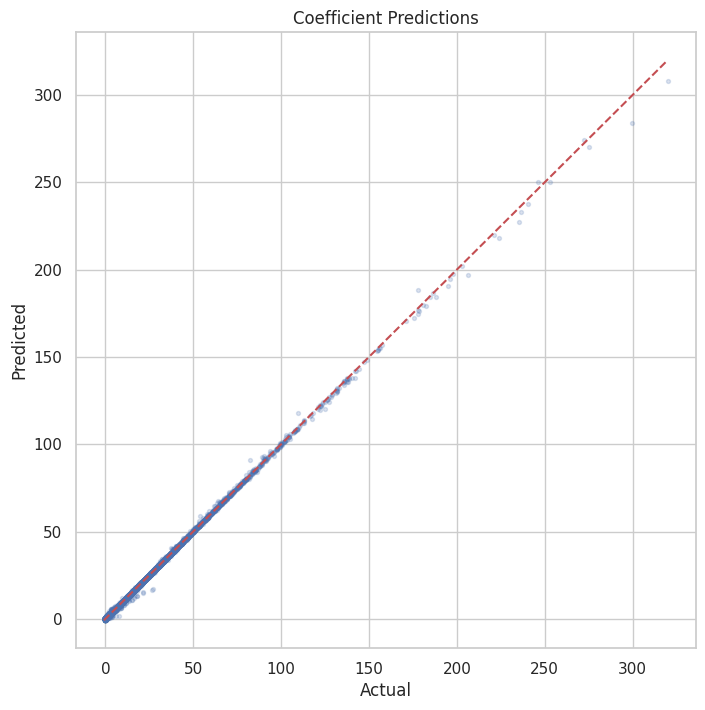

In [2]:
plt.figure(figsize=(8,8))

plt.scatter(
    all_coeff_true,
    all_coeff_pred,
    alpha=0.2,
    s=8
)

lims = [
    min(all_coeff_true.min(), all_coeff_pred.min()),
    max(all_coeff_true.max(), all_coeff_pred.max())
]

plt.plot(lims, lims, 'r--')

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Coefficient Predictions")

plt.show()

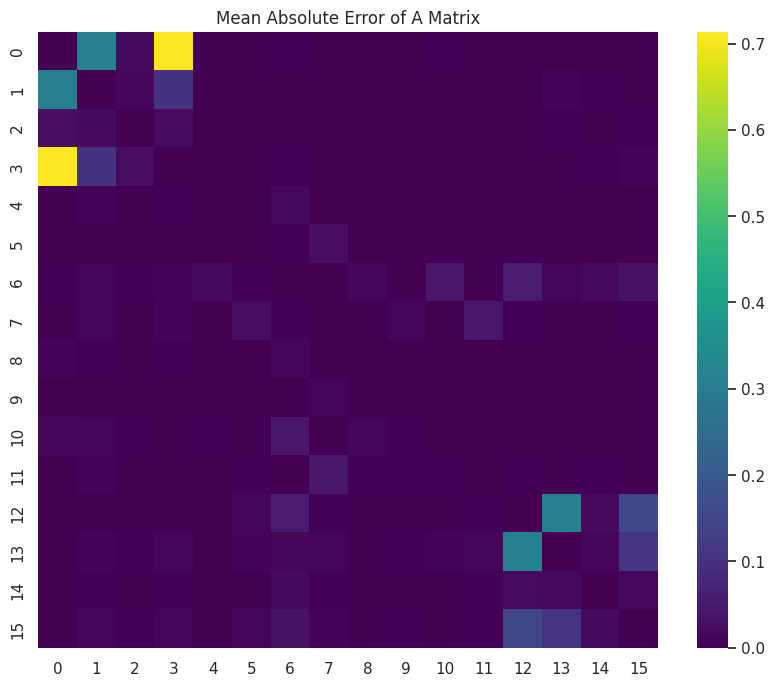

In [3]:
A_error = np.abs(all_A_true - all_A_pred)

mean_A_error = A_error.mean(axis=0)

plt.figure(figsize=(10,8))

sns.heatmap(
    mean_A_error,
    cmap="viridis"
)

plt.title("Mean Absolute Error of A Matrix")
plt.show()

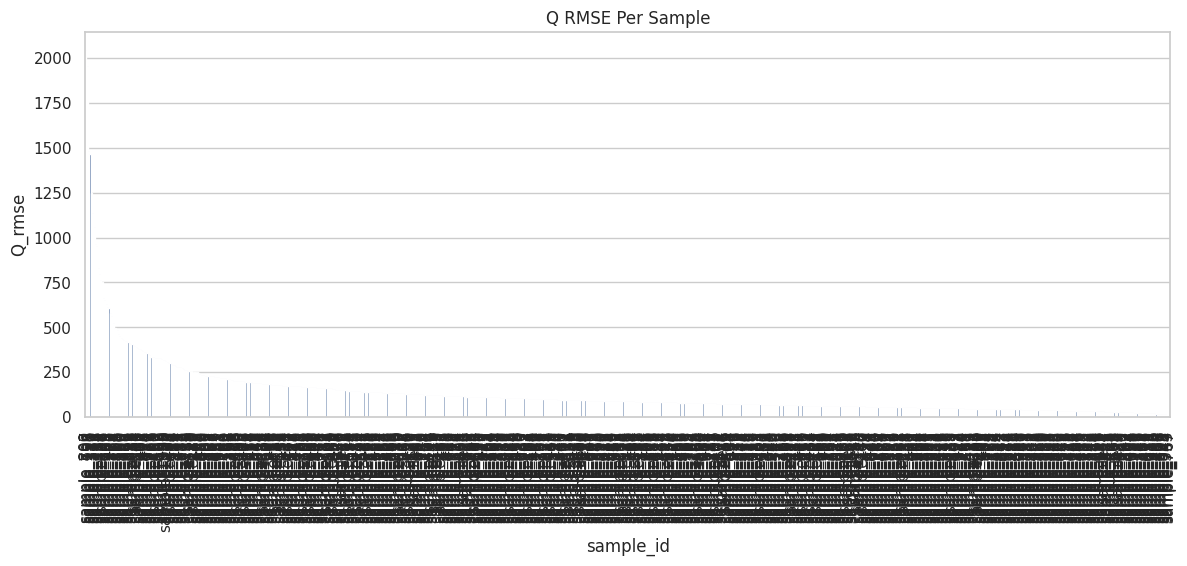

In [4]:
metrics_df = metrics_df.sort_values(
    "Q_rmse",
    ascending=False
)

plt.figure(figsize=(14,5))

sns.barplot(
    data=metrics_df,
    x="sample_id",
    y="Q_rmse"
)

plt.xticks(rotation=90)

plt.title("Q RMSE Per Sample")
plt.show()

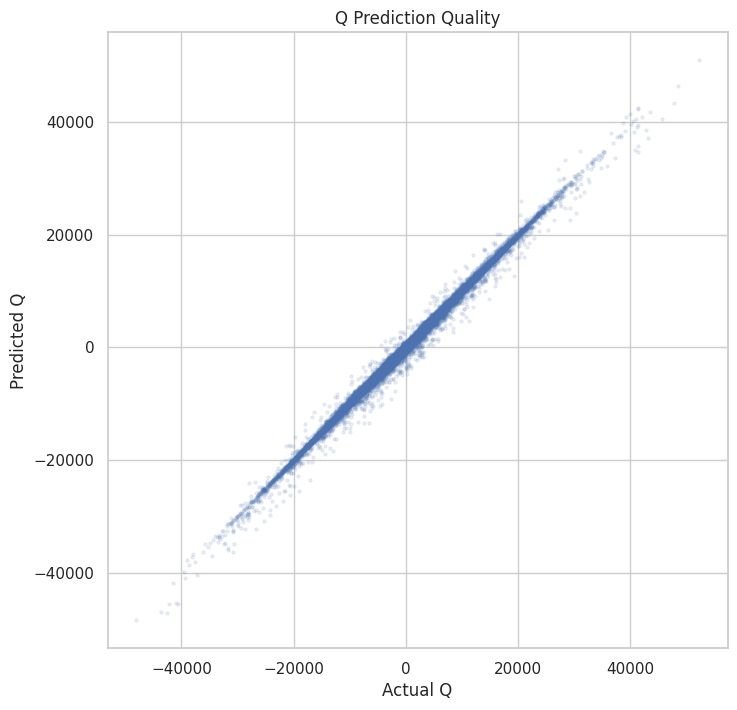

In [5]:
plt.figure(figsize=(8,8))

plt.scatter(
    all_Q_true.flatten(),
    all_Q_pred.flatten(),
    alpha=0.1,
    s=5
)

lims = [
    min(all_Q_true.min(), all_Q_pred.min()),
    max(all_Q_true.max(), all_Q_pred.max())
]

plt.plot(lims, lims, 'r--')

plt.xlabel("Actual Q")
plt.ylabel("Predicted Q")

plt.title("Q Prediction Quality")

plt.show()

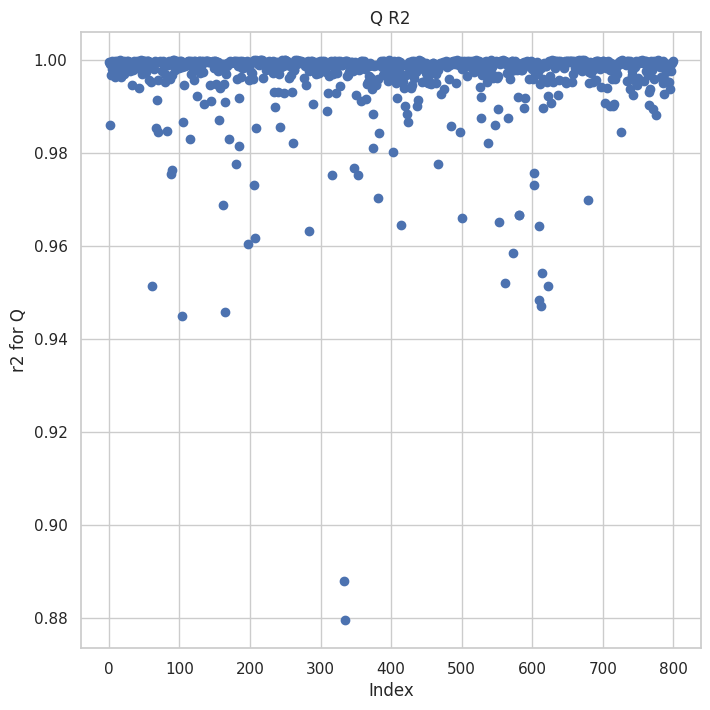

In [26]:
# Extract "Q_r2" from each dictionary in the list
q_r2_values = [item["Q_r2"] for item in results]

plt.figure(figsize=(8,8))

plt.scatter(
    np.arange(0, len(q_r2_values), 1),
    np.array(q_r2_values)
)

plt.xlabel("Index")
plt.ylabel("r2 for Q")
plt.title("Q R2")
plt.show()

In [28]:
sid_r2_less_than_90 = [item["sample_id"] for item in results if item["Q_r2"]<0.98]
print(sid_r2_less_than_90)

['sample_163', 'sample_195', 'sample_196', 'sample_213', 'sample_28', 'sample_282', 'sample_30', 'sample_32', 'sample_33', 'sample_330', 'sample_42', 'sample_457', 'sample_475', 'sample_476', 'sample_490', 'sample_495', 'sample_523', 'sample_569', 'sample_624', 'sample_67', 'sample_731', 'sample_74', 'sample_754', 'sample_766', 'sample_767', 'sample_789', 'sample_79', 'sample_797', 'sample_798', 'sample_80', 'sample_800', 'sample_811', 'sample_867']


In [29]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

# =====================================================
# Load data
# =====================================================

with open("output/botorch_test/per_sample_results_test.json", "r") as f:
    data = json.load(f)

sample_ids = list(data.keys())

# =====================================================
# Containers
# =====================================================

results = []

all_coeff_true = []
all_coeff_pred = []

all_A_true = []
all_A_pred = []

all_Q_true = []
all_Q_pred = []

# =====================================================
# Parse samples
# =====================================================

for sid, sample in data.items():

    coeff_true = np.array(sample["a_matrix_coefficients"])
    coeff_pred = np.array(sample["a_matrix_coefficients_pred"])

    A_true = np.array(sample["a_matrix"])
    A_pred = np.array(sample["a_matrix_pred"])

    Q_true = np.array(sample["q_matrix"])
    Q_pred = np.array(sample["q_pred"])

    all_coeff_true.extend(coeff_true)
    all_coeff_pred.extend(coeff_pred)

    all_A_true.append(A_true)
    all_A_pred.append(A_pred)

    all_Q_true.append(Q_true)
    all_Q_pred.append(Q_pred)

    coeff_rmse = np.sqrt(mean_squared_error(coeff_true, coeff_pred))

    A_rmse = np.sqrt(np.mean((A_true - A_pred)**2))

    Q_rmse = np.sqrt(np.mean((Q_true - Q_pred)**2))

    A_fro = (
        np.linalg.norm(A_true - A_pred, 'fro')
        /
        np.linalg.norm(A_true, 'fro')
    )

    Q_fro = (
        np.linalg.norm(Q_true - Q_pred, 'fro')
        /
        np.linalg.norm(Q_true, 'fro')
    )

    
    # Method A: Using Scikit-Learn (Recommended)
    try:
        q_r2 = r2_score(Q_true, Q_pred)
    except:
        print(sid)

    results.append({
        "sample_id": sid,
        "coeff_rmse": coeff_rmse,
        "A_rmse": A_rmse,
        "Q_rmse": Q_rmse,
        "A_fro_error": A_fro,
        "Q_fro_error": Q_fro,
        "Q_r2" : q_r2
    })

metrics_df = pd.DataFrame(results)

all_coeff_true = np.array(all_coeff_true)
all_coeff_pred = np.array(all_coeff_pred)

all_A_true = np.stack(all_A_true)
all_A_pred = np.stack(all_A_pred)

all_Q_true = np.stack(all_Q_true)
all_Q_pred = np.stack(all_Q_pred)

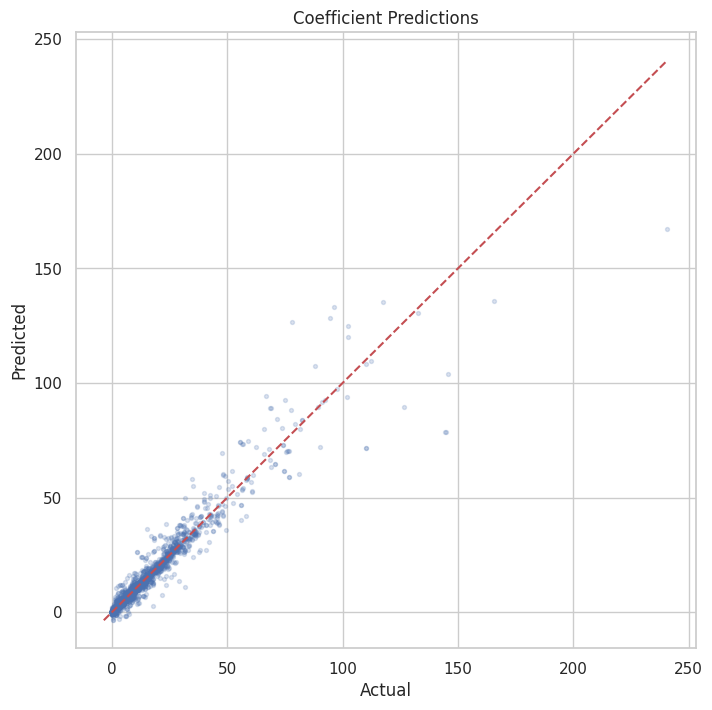

In [30]:
plt.figure(figsize=(8,8))

plt.scatter(
    all_coeff_true,
    all_coeff_pred,
    alpha=0.2,
    s=8
)

lims = [
    min(all_coeff_true.min(), all_coeff_pred.min()),
    max(all_coeff_true.max(), all_coeff_pred.max())
]

plt.plot(lims, lims, 'r--')

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Coefficient Predictions")

plt.show()

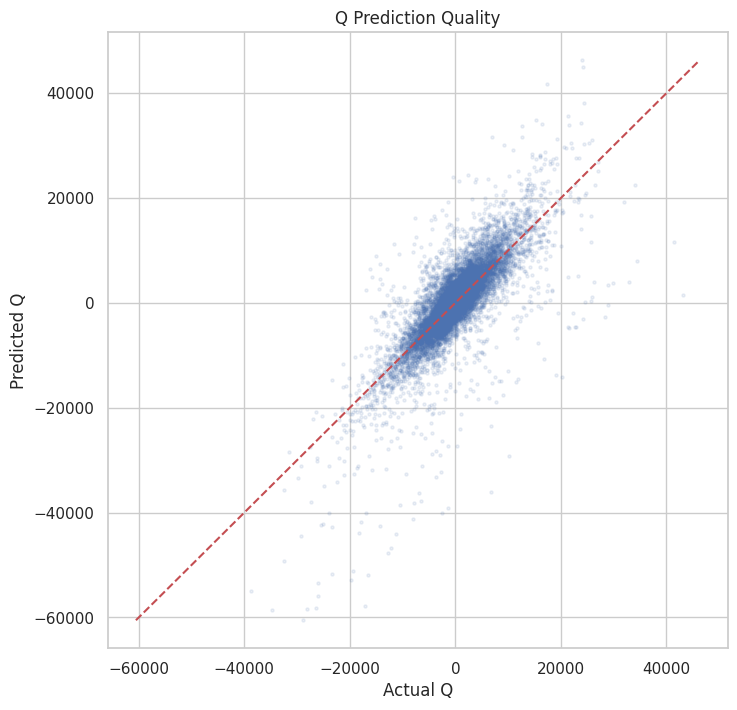

In [31]:
plt.figure(figsize=(8,8))

plt.scatter(
    all_Q_true.flatten(),
    all_Q_pred.flatten(),
    alpha=0.1,
    s=5
)

lims = [
    min(all_Q_true.min(), all_Q_pred.min()),
    max(all_Q_true.max(), all_Q_pred.max())
]

plt.plot(lims, lims, 'r--')

plt.xlabel("Actual Q")
plt.ylabel("Predicted Q")

plt.title("Q Prediction Quality")

plt.show()

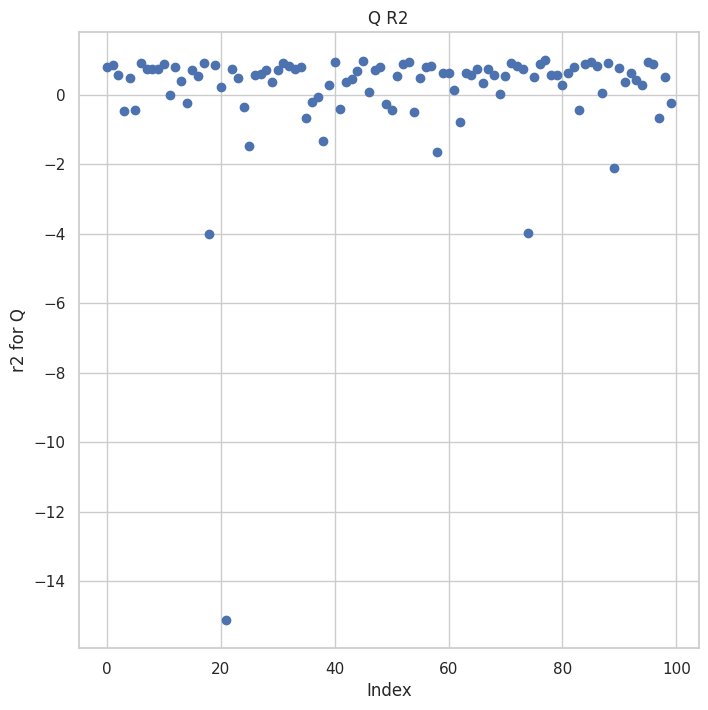

In [32]:
# Extract "Q_r2" from each dictionary in the list
q_r2_values = [item["Q_r2"] for item in results]

plt.figure(figsize=(8,8))

plt.scatter(
    np.arange(0, len(q_r2_values), 1),
    np.array(q_r2_values)
)

plt.xlabel("Index")
plt.ylabel("r2 for Q")
plt.title("Q R2")
plt.show()

In [34]:
sid_r2_less_than_95 = [item["sample_id"] for item in results if item["Q_r2"]<0.95 and item["Q_r2"]>.50]
sid_r2_negative = [item["sample_id"] for item in results if item["Q_r2"]<0]
sid_r2_less_than_1 = [item["sample_id"] for item in results if item["Q_r2"]>0.95 and item["Q_r2"]<1]
sid_r2_less_than_50 = [item["sample_id"] for item in results if item["Q_r2"]<0.5 and item["Q_r2"]>0]


print(f"number of test samples with r2 closer to 1 are: {len(sid_r2_less_than_1)} and the samples are {sid_r2_less_than_1}" )
print(f"number of test samples with r2 between 0.5 and 0.95 are: {len(sid_r2_less_than_95)} and the samples are {sid_r2_less_than_95}" )
print(f"number of test samples with r2 between 0 and 0.5 are: {len(sid_r2_less_than_50)} and the samples are {sid_r2_less_than_50}" )
print(f"number of test samples with r2 negative are: {len(sid_r2_negative)} and the samples are {sid_r2_negative}" )


number of test samples with r2 closer to 1 are: 2 and the samples are ['sample_51', 'sample_760']
number of test samples with r2 between 0.5 and 0.95 are: 56 and the samples are ['sample_109', 'sample_140', 'sample_146', 'sample_171', 'sample_184', 'sample_185', 'sample_192', 'sample_208', 'sample_24', 'sample_26', 'sample_260', 'sample_27', 'sample_292', 'sample_320', 'sample_341', 'sample_352', 'sample_356', 'sample_365', 'sample_388', 'sample_404', 'sample_41', 'sample_412', 'sample_47', 'sample_506', 'sample_527', 'sample_532', 'sample_558', 'sample_562', 'sample_564', 'sample_605', 'sample_618', 'sample_634', 'sample_644', 'sample_657', 'sample_658', 'sample_663', 'sample_683', 'sample_688', 'sample_718', 'sample_724', 'sample_729', 'sample_744', 'sample_755', 'sample_758', 'sample_768', 'sample_774', 'sample_806', 'sample_814', 'sample_855', 'sample_856', 'sample_861', 'sample_881', 'sample_900', 'sample_908', 'sample_950', 'sample_964']
number of test samples with r2 between 0 a